> **Daffa was here**

In [1]:
from pathlib import Path
import json
import os
import random

import numpy as np
import pandas as pd

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

currentRoot = Path.cwd().resolve()
projectRoot = currentRoot.parent if currentRoot.name == 'notebooks' else currentRoot
if not (projectRoot / 'notebooks').exists():
    raise RuntimeError('Run this notebook from the project root or notebooks directory.')

dataRoot = projectRoot / 'data'
rawRoot = dataRoot / 'raw'
interimRoot = dataRoot / 'interim'
processedRoot = dataRoot / 'processed'
figureRoot = projectRoot / 'reports' / 'figures'
for outputRoot in (rawRoot, interimRoot, processedRoot, figureRoot):
    outputRoot.mkdir(parents=True, exist_ok=True)

configuredRawRoot = os.environ.get('SKIN_DATA_ROOT')
rawCandidates = [Path(configuredRawRoot).expanduser()] if configuredRawRoot else []
rawCandidates.extend([rawRoot, projectRoot.parent / 'Data'])

def containsDatasetFiles(path: Path) -> bool:
    datasetSuffixes = {'.csv', '.zip', '.jpg', '.jpeg', '.png', '.tif', '.tiff'}
    return path.exists() and any(
        candidate.is_file() and candidate.suffix.lower() in datasetSuffixes
        for candidate in path.rglob('*')
    )

sourceDataRoot = next((path.resolve() for path in rawCandidates if containsDatasetFiles(path)), None)
if sourceDataRoot is None:
    raise FileNotFoundError('No raw dataset found. Populate data/raw or set SKIN_DATA_ROOT.')

def toProjectPath(path: Path) -> str:
    return Path(os.path.relpath(path.resolve(), projectRoot)).as_posix()

def fromProjectPath(pathValue: str) -> Path:
    return (projectRoot / Path(pathValue)).resolve()

print(f'Project root: {projectRoot}')
print(f'Raw dataset root: {sourceDataRoot}')

Project root: D:\sunib\Research\Skin\skin-domain-shift
Raw dataset root: D:\sunib\Research\Skin\Data


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='paper')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 10})

requiredOutputs = {
    'clinicalSix': processedRoot / 'clinicalSixClass.csv',
    'clinicalFive': processedRoot / 'clinicalFiveClass.csv',
    'isicFive': processedRoot / 'isicFiveClass.csv',
    'clinicalTrain': processedRoot / 'clinicalTrain.csv',
    'clinicalVal': processedRoot / 'clinicalVal.csv',
    'clinicalTest': processedRoot / 'clinicalTest.csv',
    'excluded': processedRoot / 'excludedSamples.csv',
    'exactDuplicates': processedRoot / 'exactDuplicates.csv',
    'nearDuplicates': processedRoot / 'nearDuplicateCandidates.csv',
}
for outputName, outputPath in requiredOutputs.items():
    if not outputPath.exists():
        raise FileNotFoundError(f'Run previous notebooks first; missing {outputPath.name}.')

frames = {name: pd.read_csv(path) for name, path in requiredOutputs.items()}
splitReport = json.loads((processedRoot / 'splitReport.json').read_text(encoding='utf-8'))
validationReport = json.loads((interimRoot / 'validationReport.json').read_text(encoding='utf-8'))
duplicateReport = json.loads((processedRoot / 'duplicateReport.json').read_text(encoding='utf-8'))

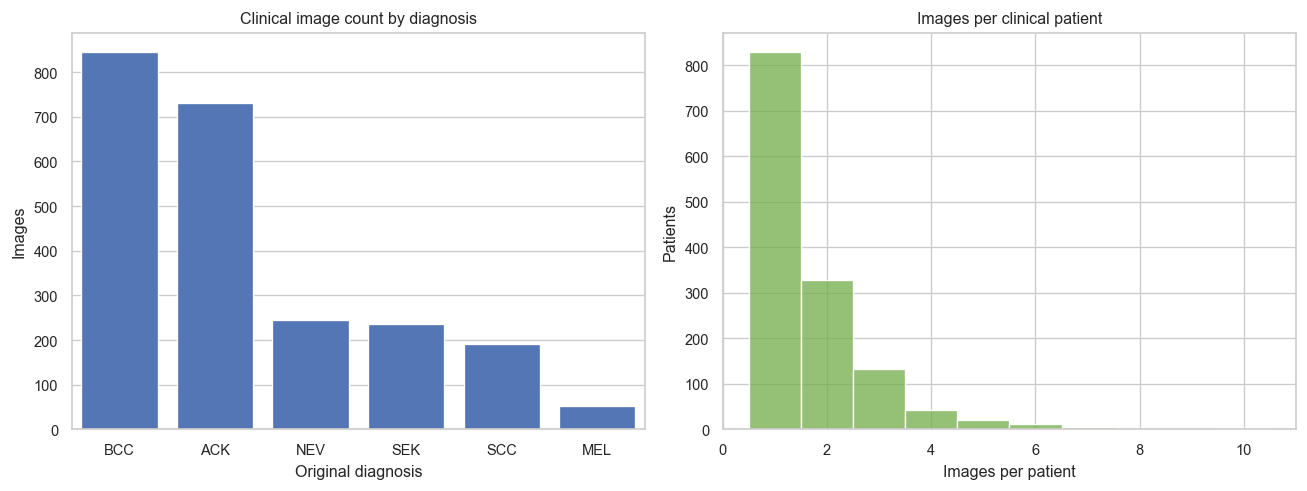

Clinical six-class images: 2,298
Clinical five-class images: 2,063
Unique clinical patients: 1,373
Multi-image patients: 544
Maximum/minimum class imbalance ratio: 16.25:1


In [3]:
clinicalSix = frames['clinicalSix']
clinicalFive = frames['clinicalFive']
splitData = pd.concat([frames['clinicalTrain'], frames['clinicalVal'], frames['clinicalTest']], ignore_index=True)

classCounts = clinicalSix['originalLabel'].value_counts().sort_values(ascending=False)
patientCountsByClass = clinicalSix.groupby('originalLabel')['patientId'].nunique().sort_values(ascending=False)
patientImageCounts = clinicalSix.groupby('patientId').size()
imbalanceRatio = float(classCounts.max() / classCounts.min())

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.barplot(x=classCounts.index, y=classCounts.values, ax=axes[0], color='#4472C4')
axes[0].set(title='Clinical image count by diagnosis', xlabel='Original diagnosis', ylabel='Images')
sns.histplot(patientImageCounts, discrete=True, ax=axes[1], color='#70AD47')
axes[1].set(title='Images per clinical patient', xlabel='Images per patient', ylabel='Patients')
figure.tight_layout()
classPatientFigurePath = figureRoot / 'clinicalClassAndPatientDistribution.png'
figure.savefig(classPatientFigurePath, bbox_inches='tight')
plt.show()

print(f'Clinical six-class images: {len(clinicalSix):,}')
print(f'Clinical five-class images: {len(clinicalFive):,}')
print(f'Unique clinical patients: {clinicalSix.patientId.nunique():,}')
print(f'Multi-image patients: {int((patientImageCounts > 1).sum()):,}')
print(f'Maximum/minimum class imbalance ratio: {imbalanceRatio:.2f}:1')

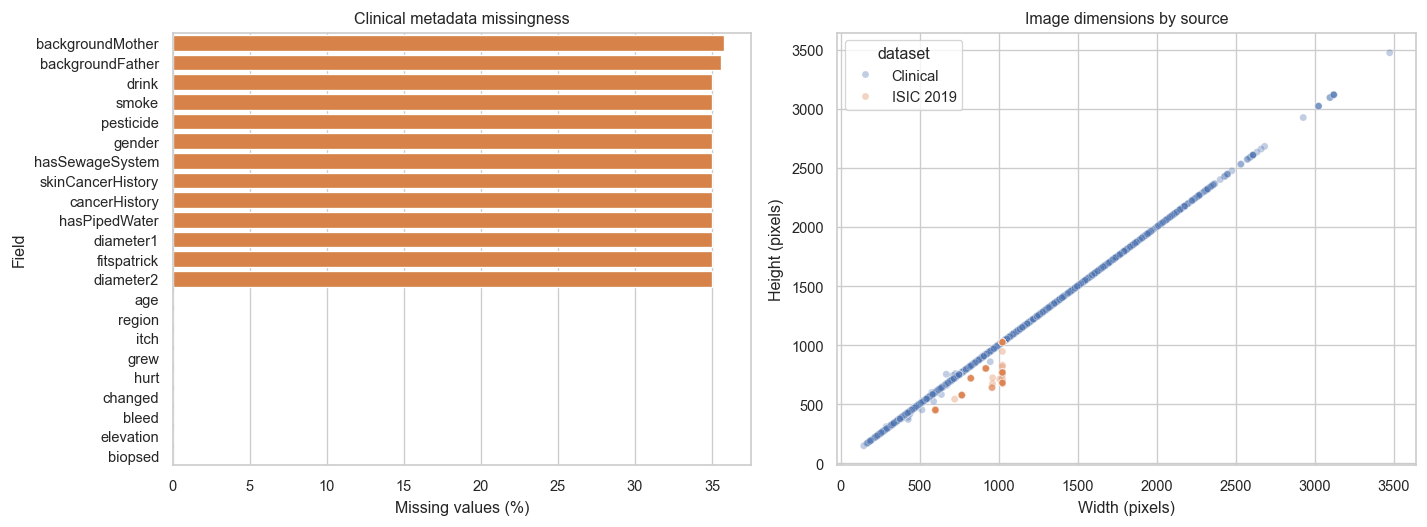

In [4]:
optionalClinicalColumns = [
    'smoke', 'drink', 'backgroundFather', 'backgroundMother', 'age', 'pesticide', 'gender',
    'skinCancerHistory', 'cancerHistory', 'hasPipedWater', 'hasSewageSystem', 'fitspatrick',
    'region', 'diameter1', 'diameter2', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'biopsed',
]
availableClinicalColumns = [column for column in optionalClinicalColumns if column in clinicalSix.columns]
missingMetadata = (clinicalSix[availableClinicalColumns].isna().mean() * 100).sort_values(ascending=False)
geometryData = pd.concat([
    clinicalSix.assign(dataset='Clinical'),
    pd.read_csv(interimRoot / 'isicValidated.csv', low_memory=False).assign(dataset='ISIC 2019'),
], ignore_index=True, sort=False)
geometryData['aspectRatio'] = geometryData['imageWidth'] / geometryData['imageHeight']

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=missingMetadata.values, y=missingMetadata.index, ax=axes[0], color='#ED7D31')
axes[0].set(title='Clinical metadata missingness', xlabel='Missing values (%)', ylabel='Field')
sampledGeometry = pd.concat([
    frame.sample(min(len(frame), 5000), random_state=RANDOM_SEED)
    for _, frame in geometryData.groupby('dataset', sort=True)
], ignore_index=True)
sns.scatterplot(data=sampledGeometry, x='imageWidth', y='imageHeight', hue='dataset', alpha=0.35, s=18, ax=axes[1])
axes[1].set(title='Image dimensions by source', xlabel='Width (pixels)', ylabel='Height (pixels)')
figure.tight_layout()
metadataGeometryFigurePath = figureRoot / 'metadataMissingnessAndImageGeometry.png'
figure.savefig(metadataGeometryFigurePath, bbox_inches='tight')
plt.show()

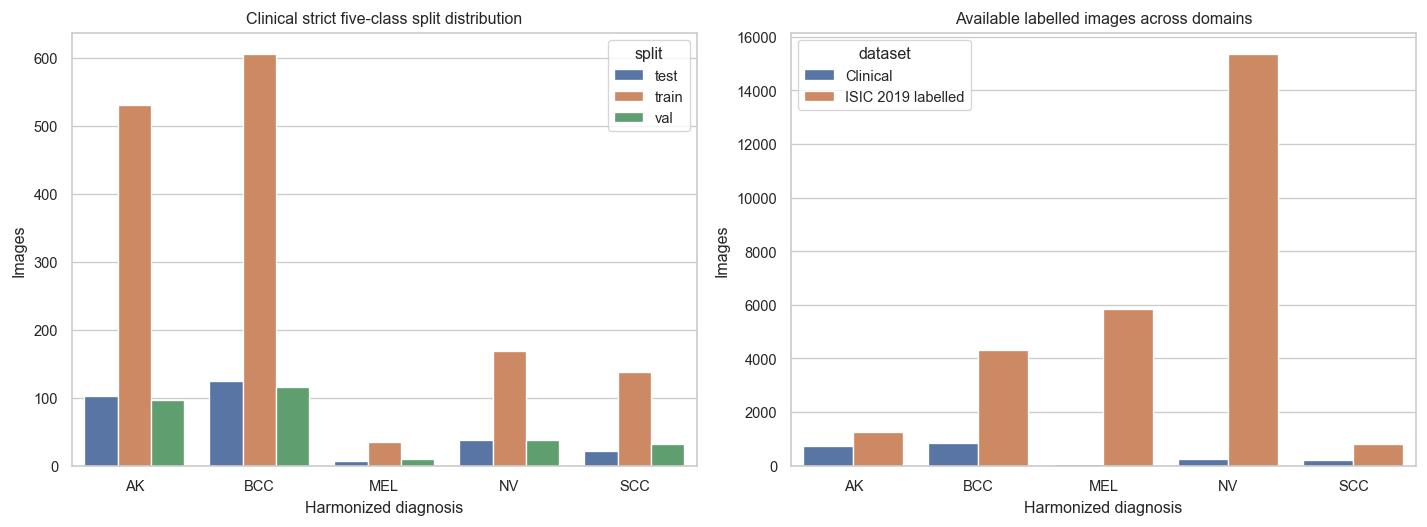

In [5]:
splitCounts = splitData.groupby(['split', 'harmonizedLabel']).size().reset_index(name='imageCount')
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=splitCounts, x='harmonizedLabel', y='imageCount', hue='split', ax=axes[0])
axes[0].set(title='Clinical strict five-class split distribution', xlabel='Harmonized diagnosis', ylabel='Images')

domainCounts = pd.DataFrame({
    'Clinical': clinicalFive['harmonizedLabel'].value_counts(),
    'ISIC 2019 labelled': frames['isicFive']['harmonizedLabel'].value_counts(),
}).fillna(0).reindex(['AK', 'BCC', 'MEL', 'NV', 'SCC']).reset_index(names='harmonizedLabel')
domainLong = domainCounts.melt(id_vars='harmonizedLabel', var_name='dataset', value_name='imageCount')
sns.barplot(data=domainLong, x='harmonizedLabel', y='imageCount', hue='dataset', ax=axes[1])
axes[1].set(title='Available labelled images across domains', xlabel='Harmonized diagnosis', ylabel='Images')
figure.tight_layout()
splitDomainFigurePath = figureRoot / 'splitAndCrossDomainDistribution.png'
figure.savefig(splitDomainFigurePath, bbox_inches='tight')
plt.show()